Install and imports

In [1]:
!pip install transformers --quiet

import os, json, time, math, random
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt

import transformers
from transformers import ViTMAEConfig, ViTMAEModel, ViTMAEForPreTraining

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("transformers:", transformers.__version__, "| torch:", torch.__version__)

Device: cuda
transformers: 5.0.0 | torch: 2.10.0+cu128


Load Part A split

In [2]:
SPLIT_PATH = "/kaggle/input/notebooks/yeamins/438-assignment-a/split.json"
DATA_ROOT  = "/kaggle/input/datasets/yeamins/ar-plaqsegm1-ultrasound-segmentation/Ar-PlaqSegm1 First Argentine database of B-mode ul"

with open(SPLIT_PATH) as f:
    split = json.load(f)

def fix_paths(records, new_root):
    fixed = []
    for rec in records:
        r = rec.copy()
        for key in ["img_path", "mask_path"]:
            parts = r[key].replace("\\", "/").split("/")
            r[key] = os.path.join(new_root, parts[-2], parts[-1])
        fixed.append(r)
    return fixed

train_records = fix_paths(split["train"], DATA_ROOT)   # unlabeled pretraining — used in THIS notebook
val_records   = fix_paths(split["val"],   DATA_ROOT)   # labeled fine-tuning  — used in the downstream notebook
test_records  = fix_paths(split["test"],  DATA_ROOT)   # monitoring + final eval — used in the downstream notebook
MASK_THRESHOLD = split["mask_threshold"]

print(f"Train (unlabeled): {len(train_records)}")
print(f"Val (labeled):     {len(val_records)}")
print(f"Test (eval):       {len(test_records)}")

Train (unlabeled): 416
Val (labeled):     73
Test (eval):       48


Pretraining Dataset

In [3]:
class MAEPretrainDataset(Dataset):
    """Yields a single augmented view per image (images only, no masks) —
    masking is applied inside ViTMAEForPreTraining, not here."""
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        img = cv2.imread(self.records[idx]["img_path"], cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)   # 3-channel for ViT
        img = Image.fromarray(img)
        return self.transform(img)

IMG_SIZE_SSL = 224  # fixed by the ViT-Base/16 checkpoint's learned position embeddings

mae_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE_SSL, scale=(0.2, 1.0), interpolation=T.InterpolationMode.BICUBIC),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

pretrain_ds = MAEPretrainDataset(train_records, mae_transform)
pretrain_loader = DataLoader(
    pretrain_ds, batch_size=32, shuffle=True,
    num_workers=2, drop_last=True, pin_memory=True
)
print(f"Pretrain batches per epoch: {len(pretrain_loader)}")

Pretrain batches per epoch: 13


MAE model — ViT-Base/16 encoder + lightweight reconstruction decoder (ImageNet-pretrained checkpoint, continued pretraining)

In [4]:
MAE_CHECKPOINT = "facebook/vit-mae-base"

model = ViTMAEForPreTraining.from_pretrained(MAE_CHECKPOINT)
model.config.mask_ratio = 0.75   # official MAE default — report at viva
model.to(device)

print(f"Params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")
print(f"Patch size: {model.config.patch_size} | Hidden dim: {model.config.hidden_size} | Mask ratio: {model.config.mask_ratio}")

config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/448M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/334 [00:00<?, ?it/s]

Params: 111.9M
Patch size: 16 | Hidden dim: 768 | Mask ratio: 0.75


Sanity Check

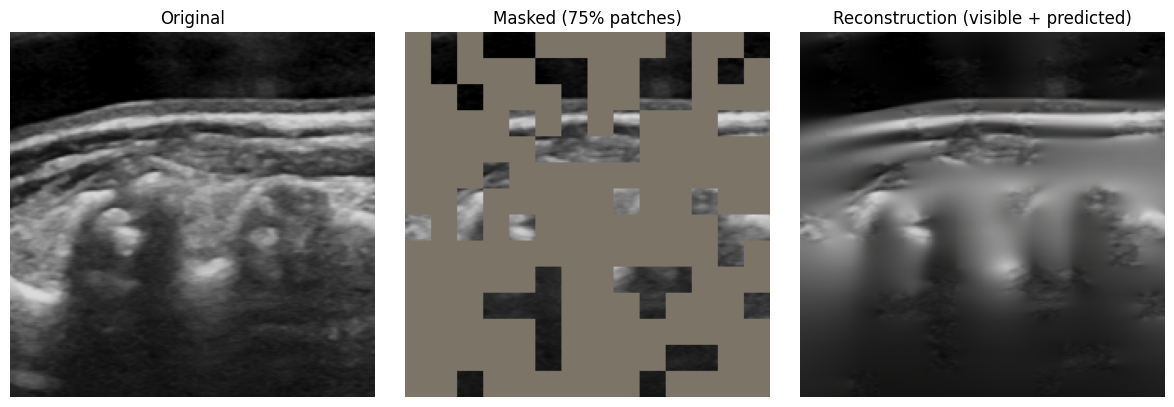

ViTMAEForPreTraining(
  (vit): ViTMAEModel(
    (embeddings): ViTMAEEmbeddings(
      (patch_embeddings): ViTMAEPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
    )
    (encoder): ViTMAEEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTMAELayer(
          (attention): ViTMAEAttention(
            (attention): ViTMAESelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTMAESelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTMAEIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermediate_act_fn): GELUActivat

In [5]:
model.eval()
sample_img = pretrain_ds[0].unsqueeze(0).to(device)
with torch.no_grad():
    out = model(pixel_values=sample_img)

def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0,1).permute(1,2,0).numpy()

patch_size = model.config.patch_size
mask = out.mask.detach().cpu()                                     # [1, num_patches], 1 = masked
mask = mask.unsqueeze(-1).repeat(1, 1, patch_size**2 * 3)
mask = model.unpatchify(mask).cpu()                                 # [1,3,H,W] in {0,1}
recon = model.unpatchify(out.logits).detach().cpu()

orig   = sample_img.cpu()
masked = orig * (1 - mask)
pasted = orig * (1 - mask) + recon * mask                           # visible patches kept, masked ones predicted

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(denorm(orig[0]));   ax[0].set_title("Original");                                    ax[0].axis("off")
ax[1].imshow(denorm(masked[0])); ax[1].set_title(f"Masked ({model.config.mask_ratio:.0%} patches)"); ax[1].axis("off")
ax[2].imshow(denorm(pasted[0])); ax[2].set_title("Reconstruction (visible + predicted)");        ax[2].axis("off")
plt.tight_layout(); plt.savefig("/kaggle/working/mae_masking_sanity.png", dpi=150); plt.show()
model.train()

Pretraining Loop

In [6]:
PRETRAIN_CONFIG = {
    "epochs": 50,
    "batch_size": 32,
    "lr": 1.5e-4,
    "weight_decay": 0.05,
    "mask_ratio": 0.75,           # fraction of patches masked — report at viva
    "patch_size": model.config.patch_size,
    "img_size": IMG_SIZE_SSL,
    "optimizer": "AdamW",
    "checkpoint": MAE_CHECKPOINT,
    "loss": "normalized per-patch pixel MSE (masked patches only)",
}

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=PRETRAIN_CONFIG["lr"],
    weight_decay=PRETRAIN_CONFIG["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PRETRAIN_CONFIG["epochs"]
)

pretrain_losses = []
epoch_times = []
model.train()

for epoch in range(PRETRAIN_CONFIG["epochs"]):
    t0 = time.time()
    epoch_loss = 0.0

    for imgs in pretrain_loader:
        imgs = imgs.to(device)
        outputs = model(pixel_values=imgs)     # masking + encode + decode + loss, all internal
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    avg_loss = epoch_loss / len(pretrain_loader)
    dt = time.time() - t0
    pretrain_losses.append(avg_loss)
    epoch_times.append(dt)
    print(f"Epoch {epoch+1:02d}/50 | recon loss: {avg_loss:.4f} | {dt:.1f}s")

if max(epoch_times) > 600:
    print("NOTE: per-epoch pretrain time exceeded 10 min — this confirms the split into pretrain + downstream notebooks (Sec 3.2).")

# Save encoder only (vit backbone) — decoder/reconstruction head is discarded after pretraining
torch.save(model.vit.state_dict(), "/kaggle/working/mae_encoder.pt")

# Save pretrain metadata so the downstream notebook can report it without re-running pretraining
pretrain_meta = {
    "checkpoint": MAE_CHECKPOINT,
    "mask_ratio": PRETRAIN_CONFIG["mask_ratio"],
    "patch_size": PRETRAIN_CONFIG["patch_size"],
    "epochs": PRETRAIN_CONFIG["epochs"],
    "epoch_times_sec": epoch_times,
    "pretrain_losses": pretrain_losses,
    "mean_epoch_sec": float(np.mean(epoch_times)),
    "total_min": float(sum(epoch_times)/60),
}
with open("/kaggle/working/mae_pretrain_meta.json", "w") as f:
    json.dump(pretrain_meta, f, indent=2)

print(f"\nMean epoch time: {np.mean(epoch_times):.1f}s")
print(f"Total pretrain time: {sum(epoch_times)/60:.1f} min")

Epoch 01/50 | recon loss: 0.1313 | 8.5s
Epoch 02/50 | recon loss: 0.1145 | 8.0s
Epoch 03/50 | recon loss: 0.1149 | 8.1s
Epoch 04/50 | recon loss: 0.1110 | 8.2s
Epoch 05/50 | recon loss: 0.1116 | 8.3s
Epoch 06/50 | recon loss: 0.1113 | 8.4s
Epoch 07/50 | recon loss: 0.1101 | 8.5s
Epoch 08/50 | recon loss: 0.1078 | 8.7s
Epoch 09/50 | recon loss: 0.1041 | 8.8s
Epoch 10/50 | recon loss: 0.1088 | 8.8s
Epoch 11/50 | recon loss: 0.1042 | 8.9s
Epoch 12/50 | recon loss: 0.1043 | 9.0s
Epoch 13/50 | recon loss: 0.1068 | 9.1s
Epoch 14/50 | recon loss: 0.1072 | 9.2s
Epoch 15/50 | recon loss: 0.1049 | 9.2s
Epoch 16/50 | recon loss: 0.1061 | 9.3s
Epoch 17/50 | recon loss: 0.1057 | 9.4s
Epoch 18/50 | recon loss: 0.1062 | 9.5s
Epoch 19/50 | recon loss: 0.1054 | 9.5s
Epoch 20/50 | recon loss: 0.1019 | 9.6s
Epoch 21/50 | recon loss: 0.1026 | 9.7s
Epoch 22/50 | recon loss: 0.1015 | 9.8s
Epoch 23/50 | recon loss: 0.1012 | 9.9s
Epoch 24/50 | recon loss: 0.1017 | 10.0s
Epoch 25/50 | recon loss: 0.0995 | 10.0

Plot pretraining loss

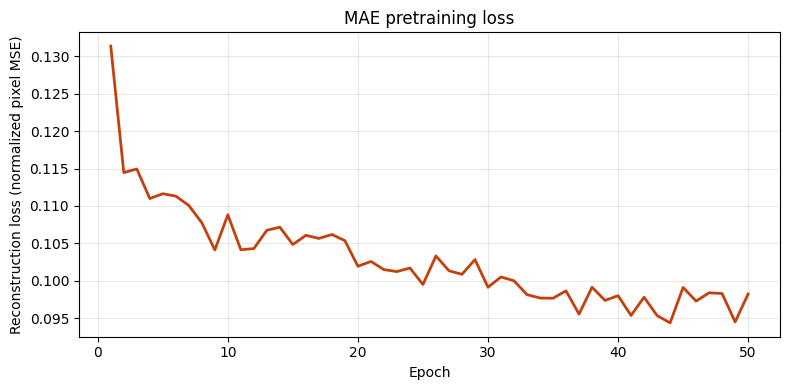

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, PRETRAIN_CONFIG["epochs"]+1), pretrain_losses, color="#C2410C", linewidth=2)
ax.set_xlabel("Epoch"); ax.set_ylabel("Reconstruction loss (normalized pixel MSE)")
ax.set_title("MAE pretraining loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/kaggle/working/mae_pretrain_loss.png", dpi=150)
plt.show()